In [1]:
import pandas as pd

X_train = pd.read_csv("data/processed/X_train.csv")
X_test = pd.read_csv("data/processed/X_test.csv")
y_train = pd.read_csv("data/processed/y_train.csv").squeeze()
y_test = pd.read_csv("data/processed/y_test.csv").squeeze()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1076391, 60)
X_test shape: (269098, 60)
y_train shape: (1076391,)
y_test shape: (269098,)


In [2]:
from sklearn.linear_model import LogisticRegression

# class_weight='balanced' automatically adjusts weights inversely proportional 
# to class frequencies — so the minority class (default) gets more importance
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


c:\Users\chity\OneDrive\Desktop\Credit-risk-rag-project\credit_risk_env\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit the scaler ONLY on training data (learn the mean/std from training set only)
X_train_scaled = scaler.fit_transform(X_train)

# Apply the SAME transformation to test data (using training data's mean/std, not test's own)
X_test_scaled = scaler.transform(X_test)

print("Scaling complete!")


Scaling complete!


In [4]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

model.fit(X_train_scaled, y_train)

print("Model trained successfully!")

Model trained successfully!


In [5]:
from sklearn.metrics import classification_report, roc_auc_score

# Get predictions
y_pred = model.predict(X_test_scaled)

# Get predicted probabilities (needed for ROC-AUC)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]  # probability of class 1 (default)

# Print full classification report
print(classification_report(y_test, y_pred))

# Print ROC-AUC score separately
print("ROC-AUC Score:", roc_auc_score(y_test, y_pred_proba))

              precision    recall  f1-score   support

           0       0.88      0.67      0.76    215343
           1       0.33      0.65      0.43     53755

    accuracy                           0.66    269098
   macro avg       0.60      0.66      0.60    269098
weighted avg       0.77      0.66      0.69    269098

ROC-AUC Score: 0.7168317920891358


In [6]:
# Calculate the ratio of negative to positive class for scale_pos_weight
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", scale_pos_weight)

scale_pos_weight: 4.00605065622413


In [7]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [8]:
from sklearn.metrics import classification_report, roc_auc_score

# Get predictions
y_pred_xgb = xgb_model.predict(X_test)

# Get predicted probabilities
y_pred_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Print full classification report
print(classification_report(y_test, y_pred_xgb))

# Print ROC-AUC score
print("ROC-AUC Score:", roc_auc_score(y_test, y_pred_proba_xgb))

              precision    recall  f1-score   support

           0       0.89      0.66      0.76    215343
           1       0.33      0.68      0.44     53755

    accuracy                           0.66    269098
   macro avg       0.61      0.67      0.60    269098
weighted avg       0.78      0.66      0.69    269098

ROC-AUC Score: 0.7327721497621388


In [9]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

# Take a sample for faster tuning
sample_size = 150000
X_train_sample = X_train.sample(n=sample_size, random_state=42)
y_train_sample = y_train.loc[X_train_sample.index]

print("Sample shape:", X_train_sample.shape)

Sample shape: (150000, 60)


In [10]:
param_distributions = {
    'n_estimators': [100, 200, 300],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0]
}

In [11]:
scale_pos_weight_sample = (y_train_sample == 0).sum() / (y_train_sample == 1).sum()

xgb_base = XGBClassifier(
    scale_pos_weight=scale_pos_weight_sample,
    random_state=42,
    eval_metric='logloss'
)

random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_distributions,
    n_iter=15,              # try 15 random combinations
    scoring='roc_auc',      # optimize for ROC-AUC, our key metric
    cv=3,                   # 3-fold cross-validation for each combination
    random_state=42,
    verbose=2,              # print progress so we can see it working
    n_jobs=-1                # use all CPU cores to speed this up
)

random_search.fit(X_train_sample, y_train_sample)

print("Best parameters found:", random_search.best_params_)
print("Best ROC-AUC score:", random_search.best_score_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best parameters found: {'subsample': 1.0, 'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
Best ROC-AUC score: 0.7194968913107435


In [12]:
best_params = random_search.best_params_

xgb_tuned = XGBClassifier(
    **best_params,
    scale_pos_weight=scale_pos_weight,  # using our original full-data ratio, not the sample's
    random_state=42,
    eval_metric='logloss'
)

xgb_tuned.fit(X_train, y_train)

print("Tuned model trained on full data!")

Tuned model trained on full data!


In [13]:
y_pred_tuned = xgb_tuned.predict(X_test)
y_pred_proba_tuned = xgb_tuned.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_tuned))
print("ROC-AUC Score:", roc_auc_score(y_test, y_pred_proba_tuned))


              precision    recall  f1-score   support

           0       0.89      0.64      0.75    215343
           1       0.32      0.68      0.44     53755

    accuracy                           0.65    269098
   macro avg       0.61      0.66      0.59    269098
weighted avg       0.78      0.65      0.68    269098

ROC-AUC Score: 0.7243893994161447


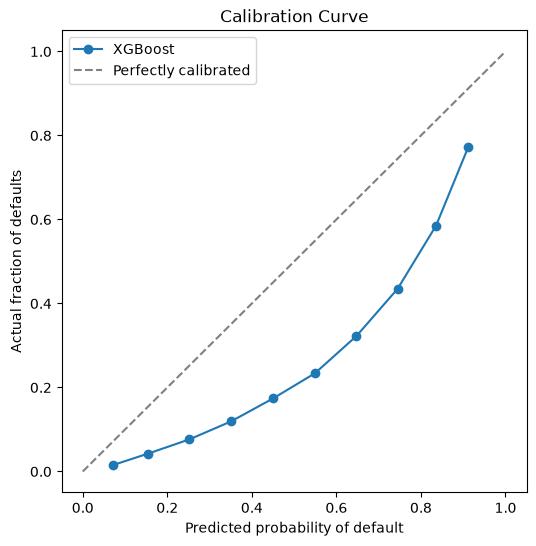

In [14]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Compare predicted probabilities to actual outcomes, in bins
prob_true, prob_pred = calibration_curve(y_test, y_pred_proba_xgb, n_bins=10)

plt.figure(figsize=(6,6))
plt.plot(prob_pred, prob_true, marker='o', label='XGBoost')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly calibrated')
plt.xlabel('Predicted probability of default')
plt.ylabel('Actual fraction of defaults')
plt.title('Calibration Curve')
plt.legend()
plt.show()

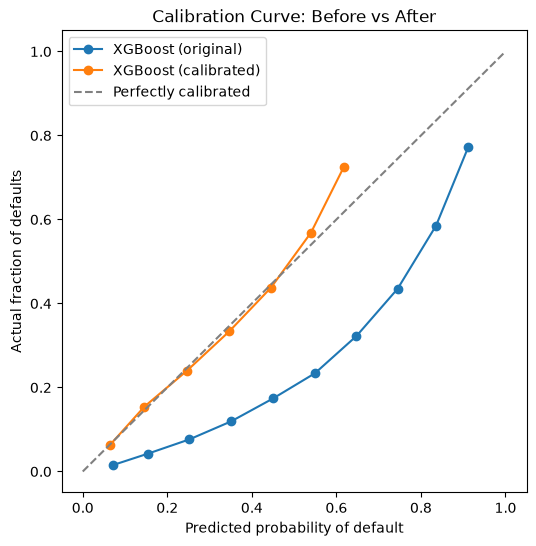

In [16]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

# Freeze our already-trained model (tells sklearn: don't retrain this, just use it as-is)
frozen_xgb = FrozenEstimator(xgb_model)

# Now calibrate on top of the frozen model
calibrated_model = CalibratedClassifierCV(frozen_xgb, method='sigmoid')
calibrated_model.fit(X_test, y_test)

# Get NEW, calibrated probabilities
y_pred_proba_calibrated = calibrated_model.predict_proba(X_test)[:, 1]

# Re-plot calibration curve to check improvement
prob_true_cal, prob_pred_cal = calibration_curve(y_test, y_pred_proba_calibrated, n_bins=10)

plt.figure(figsize=(6,6))
plt.plot(prob_pred, prob_true, marker='o', label='XGBoost (original)')
plt.plot(prob_pred_cal, prob_true_cal, marker='o', label='XGBoost (calibrated)')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly calibrated')
plt.xlabel('Predicted probability of default')
plt.ylabel('Actual fraction of defaults')
plt.title('Calibration Curve: Before vs After')
plt.legend()
plt.show()